# Métricas no supervisadas para la optimización de hiperparámetros en detectores de anomalías IoT en el borde
### Cuaderno reproducible del experimento — Belén Aedo Peña · Profesor guía: Dr. Juan Iturbe Araya

Este cuaderno recorre el experimento **desde los datos hasta los resultados**, en el mismo orden que el
Capítulo 3 de la memoria. Cada tabla y figura indica **de qué archivo sale, qué script y función lo generó y
qué parámetros de la configuración usó** (línea *Fuente*).

| | |
|---|---|
| **Qué hace este cuaderno** | lee los resultados guardados por el pipeline, **verifica** que se pueden reproducir y los presenta |
| **Qué NO hace por defecto** | no vuelve a correr las etapas largas (la optimización completa toma horas). Para hacerlo, ver *Cómo ejecutar* |
| **Cuaderno complementario** | `cuaderno_funciones.ipynb`: explica cada función del código, con ejemplos pequeños |

## Cómo ejecutar
```powershell
cd C:\Users\belen\Desktop\tesis_hpo_edge
.\.venv\Scripts\Activate.ps1            # Python 3.10
pip install -r requirements.txt           # dependencias (versiones exactas: ver sección 1)
python run_all.py                         # pipeline completo: preprocesar, splits, optimizar, evaluar, reporte
```
Luego abrir este cuaderno en VS Code o Jupyter (kernel `.venv`) y ejecutar **Run All** (≈ 1 minuto).

Interruptores de la celda siguiente:
- `VERIFICAR = True` (por defecto): vuelve a generar las particiones y a evaluar los modelos de la semilla 42, y
  compara con lo guardado (≈ 30 s).
- `REPETIR_UNA_BUSQUEDA = True`: repite una búsqueda completa de Optuna (≈ 2 min) para mostrar su reproducibilidad.

## Relación con el repositorio
El cuaderno **no reimplementa nada**: importa los módulos de `src/` y llama a sus funciones.
Los scripts numerados (`1_prepare_splits.py`, …) se cargan con `importlib.import_module`, porque un nombre que
empieza con un número no se puede importar con `import`.

| Etapa | Memoria | Script / módulo | Funciones principales | Archivos que produce |
|---|---|---|---|---|
| Datos y preprocesador | 3.1.3, 3.1.4 | `preprocessor/` (profesor) vía `run_all.py` | `etapa_preprocesar` | `Datasets/Parquet/Ton-IoT/*_processed.parquet` |
| Particiones y variables | 3.2.2, 3.2.3 | `src/1_prepare_splits.py` | `select_unsupervised`, `fit_scaler`, `stratified_halves` | `data/splits/*`, `manifest.json` |
| Detectores y umbral | 3.2.4, 3.2.5 | `src/detectors.py`, `src/search_space.py` | `IForestDetector`, `LOFDetector`, `AutoencoderDetector`, `set_threshold`, `suggest_params` | — |
| Funciones objetivo | 3.2.6 | `src/objectives.py` | `compute_objective` | — |
| Diagnóstico | 3.2.10 | `src/2_diagnose.py` | `main` | `outputs/results/diagnose_objectives*.{csv,json}` |
| Optimización | 3.2.7, 3.2.8 (etapa 1) | `src/3_optimize.py` | `run_study`, `build_baseline` | `outputs/optuna/*.json`, `outputs/models/*.pkl` |
| Medición en el borde | 3.2.8 (etapa 2) | `src/4_edge_benchmark.py` | `worker`, `meets` | `outputs/results/edge_benchmark.csv` |
| Evaluación final | 3.2.9 | `src/5_evaluate.py` | `select_entries`, `evaluate_entry`, `summarize`, `pareto_front` | `outputs/results/*.csv`, `hypothesis_check.json` |
| Tablas LaTeX | — | `src/6_report.py` | `table_*` | `outputs/tables/*.tex` |

In [1]:
VERIFICAR = True               # regenera particiones y reevalua la semilla 42 (~30 s)
REPETIR_UNA_BUSQUEDA = False   # repite iforest + silhouette, semilla 42, 100 trials (~2 min)

import hashlib, importlib, json, platform, subprocess, sys, tempfile, warnings
from datetime import datetime
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))

import common, detectors, objectives, search_space            # modulos de apoyo
ps  = importlib.import_module("1_prepare_splits")             # scripts numerados
opt = importlib.import_module("3_optimize")
ev  = importlib.import_module("5_evaluate")

cfg = common.load_config()                                    # config/experiment.yaml
RES, MOD, SPL = common.results_dir(cfg), common.models_dir(cfg), common.splits_dir(cfg)

def sha(p, n=12):
    return common.sha256_of(p)[:n]

def fuente(archivo, codigo, params=""):
    """Imprime de donde sale una tabla o figura (archivo + huella + fecha, codigo, parametros)."""
    p = Path(archivo)
    fecha = datetime.fromtimestamp(p.stat().st_mtime).strftime("%Y-%m-%d %H:%M") if p.exists() else "NO EXISTE"
    huella = sha(p) if p.exists() and p.is_file() else "-"
    print(f"Fuente: {p.relative_to(RAIZ)} (sha256 {huella}…, {fecha}) | código: {codigo}" + (f" | config: {params}" if params else ""))
print("Proyecto:", RAIZ)

Proyecto: c:\Users\belen\Desktop\tesis_hpo_edge


---
# 1. Identificación: versión del código, entorno, configuración, semillas y datos
*(Memoria 3.1.1, 3.1.2 y 3.2.11)*

In [2]:
def git(*a):
    try: return subprocess.run(["git", *a], cwd=RAIZ, capture_output=True, text=True).stdout.strip()
    except Exception: return "?"
commit = git("rev-parse", "HEAD")
pendientes = git("status", "--porcelain", "--", "src", "scripts", "config", "run_all.py", "preprocessor")
print("Repositorio: https://github.com/belen-aedo/tesis-hpo-edge")
print("Commit del código:", commit, "|", git("log", "-1", "--format=%ci %s"))
print("Etiqueta:", git("describe", "--tags", "--always"))
print("¿Código modificado sin commit?:", "SÍ  <- los resultados podrían no corresponder a este commit" if pendientes else "no")

Repositorio: https://github.com/belen-aedo/tesis-hpo-edge
Commit del código: 6f16005ed8a3608aefbe01986634764b744be43d | 2026-11-13 17:38:27 -0300 Ordenar el proyecto: scripts numerados, preprocessor incluido y cuaderno
Etiqueta: 6f16005
¿Código modificado sin commit?: no


### Entorno: versiones de esta ejecución y de cuando se entrenaron los modelos (`outputs/models/env.json`)

In [3]:
import sklearn, scipy, optuna, pyarrow, psutil
ahora = {"python": platform.python_version(), "numpy": np.__version__, "scikit-learn": sklearn.__version__,
         "scipy": scipy.__version__, "pandas": pd.__version__, "optuna": optuna.__version__,
         "pyarrow": pyarrow.__version__, "psutil": psutil.__version__, "platform": platform.platform()}
entreno = common.load_json(MOD / "env.json")
tabla = pd.DataFrame({"esta ejecución": ahora, "entrenamiento de los modelos": entreno}).fillna("-")
tabla["¿igual?"] = [("sí" if str(a) == str(b) else ("-" if b == "-" else "NO")) for a, b in zip(tabla.iloc[:, 0], tabla.iloc[:, 1])]
display(tabla)
fuente(MOD / "env.json", "3_optimize.write_env")

,esta ejecución,entrenamiento de los modelos,¿igual?
python,3.10.11,3.10.11,sí
numpy,2.2.6,2.2.6,sí
scikit-learn,1.7.2,1.7.2,sí
scipy,1.15.3,1.15.3,sí
pandas,2.3.3,-,-
optuna,5.0.0,-,-
pyarrow,25.0.1,-,-
psutil,7.2.2,-,-
platform,Windows-10-10.0.26200-SP0,Windows-10-10.0.26200-SP0,sí
tensorflow,-,-,sí


Fuente: outputs\models\env.json (sha256 ab522dbded1b…, 2026-10-12 10:41) | código: 3_optimize.write_env


### Configuración del experimento (`config/experiment.yaml`)
Es la **única fuente de parámetros**. Su huella SHA-256 identifica exactamente qué configuración se usó.

In [4]:
p = RAIZ / "config" / "experiment.yaml"
print("SHA-256 de config/experiment.yaml:", common.sha256_of(p))
clave = {
    "input.variant": cfg["input"]["variant"], "features.mode": cfg["features"]["mode"],
    "features.max_features": cfg["features"]["max_features"], "features.min_minority_freq": cfg["features"]["min_minority_freq"],
    "features.max_abs_corr": cfg["features"]["max_abs_corr"], "scaling": f"{cfg['scaling']['method']} (clip ±{cfg['scaling']['clip']})",
    "split.val_frac_of_normal": cfg["split"]["val_frac_of_normal"], "split.oracle_frac_of_test": cfg["split"]["oracle_frac_of_test"],
    "threshold.q": cfg["threshold"]["q"], "threshold.calib_frac": cfg["threshold"]["calib_frac"],
    "threshold.sensitivity_q": cfg["threshold"]["sensitivity_q"], "detectors": cfg["detectors"],
    "optimization.n_trials": cfg["optimization"]["n_trials"], "optimization.seeds": cfg["optimization"]["seeds"],
    "optimization.top_k": cfg["optimization"]["top_k"], "optimization.max_train_rows": cfg["optimization"]["max_train_rows"],
    "edge.max_latency_ms / dev_slowdown_factor": f"{cfg['edge']['max_latency_ms']} / {cfg['edge']['dev_slowdown_factor']}",
    "edge.max_cpu_percent @ flow_rate_per_s": f"{cfg['edge']['max_cpu_percent']} % @ {cfg['edge']['flow_rate_per_s']}/s",
    "edge.max_ram_mb / max_model_kb": f"{cfg['edge']['max_ram_mb']} / {cfg['edge']['max_model_kb']}",
}
pd.Series(clave, name="valor").to_frame()

SHA-256 de config/experiment.yaml: 90826f07ff50c0ad30e1e366224e875c69691f26237b39eecbb686bdea000be8


,valor
input.variant,processed
features.mode,unsupervised
features.max_features,40
features.min_minority_freq,0.001
features.max_abs_corr,0.95
scaling,standard (clip ±10.0)
split.val_frac_of_normal,0.15
split.oracle_frac_of_test,0.5
threshold.q,0.95
threshold.calib_frac,0.5


### Semillas
| Semilla | Valor | Dónde se fija | Para qué |
|---|---|---|---|
| `split.seed` (config) | 42 | `1_prepare_splits.main`, `common.split_val` | partir train/val, test_oracle/test_final y val en calibración/objetivo |
| `optimization.seeds` (config) | 42, 43, 44, 45, 46 | `3_optimize.run_study` | semilla de TPE (`TPESampler(seed)`), de `random`/`numpy` y de cada detector (`random_state`) |
| constante en código | 42 | `common.subsample` | submuestra fija de 10 000 filas de train |
| constante en código | 42 | `1_prepare_splits.select_unsupervised` (vía `split.seed`) | muestra de 20 000 filas para la correlación |
| constante en código | 0 | `objectives.objective_silhouette` | muestra de 5 000 filas para Silhouette |
| constante en código | 42 | `objectives.objective_stability`, `objective_consistency` | ruido de la estabilidad y submuestras de la consistencia |
| constante en código | 42 | `4_edge_benchmark.worker` | filas elegidas para medir en la Raspberry Pi |
| `2_diagnose.py --seed` | 0 | `2_diagnose.main` | configuraciones al azar del diagnóstico |

### Datos de entrada: archivo original de TON_IoT y salida del preprocesador

In [5]:
csv = RAIZ / "Datasets/Sources/TON-IoT/Train_Test_datasets/Train_Test_Network_dataset/Train_Test_Labels.csv"
pq_dir = common.datasets_dir(cfg) / "Parquet" / cfg["dataset"]["name"]
filas = []
for f in [csv] + sorted(pq_dir.glob("*_processed.parquet")):
    if f.exists():
        filas.append({"archivo": str(f.relative_to(RAIZ)), "MB": round(f.stat().st_size / 1e6, 1), "sha256": common.sha256_of(f)[:16] + "…"})
display(pd.DataFrame(filas))
print("Train_Test_Labels.csv es una copia sin modificar de Train_Test_Network.csv (la crea run_all.etapa_preprocesar).")
print("Preprocesador: preprocessor/preprocessor_v2, commit af5cd12 del repositorio del profesor; solo se cambian rutas en config.yaml/config.json (scripts/0_configurar_preprocessor.py).")

,archivo,MB,sha256
0,Datasets\Sources\TON-IoT\Train_Test_datasets\T...,29.9,26ddc513552de36d…
1,Datasets\Parquet\Ton-IoT\test_processed.parquet,0.9,300a04c466582eb1…
2,Datasets\Parquet\Ton-IoT\train_processed.parquet,3.1,165c80c857a9933c…


Train_Test_Labels.csv es una copia sin modificar de Train_Test_Network.csv (la crea run_all.etapa_preprocesar).
Preprocesador: preprocessor/preprocessor_v2, commit af5cd12 del repositorio del profesor; solo se cambian rutas en config.yaml/config.json (scripts/0_configurar_preprocessor.py).


---
# 2. Estado de cada etapa: qué resultados están disponibles y qué falta

In [6]:
etapas = [
    ("Preprocesador (pasos 00-03)", pq_dir / "train_processed.parquet", "3.1.3"),
    ("Particiones", SPL / "manifest.json", "3.2.3"),
    ("Diagnóstico de funciones objetivo", RES / "diagnose_objectives_summary.json", "3.2.10"),
    ("Optimización (Optuna)", RAIZ / "outputs/optuna/all_studies.json", "3.2.7"),
    ("Medición en Raspberry Pi 5", RES / "edge_benchmark.csv", "3.2.8 etapa 2"),
    ("Evaluación final", RES / "final_evaluation.csv", "3.2.9"),
    ("Frente de Pareto MCC/latencia", RES / "pareto_mcc_latencia.csv", "3.2.8"),
    ("Tablas LaTeX", RAIZ / "outputs/tables/tab_mock_balance.tex", "-"),
]
estado = pd.DataFrame([{"etapa": e, "memoria": s, "archivo": str(f.relative_to(RAIZ)),
                        "estado": "DISPONIBLE" if f.exists() else "PENDIENTE",
                        "fecha": datetime.fromtimestamp(f.stat().st_mtime).strftime("%Y-%m-%d %H:%M") if f.exists() else "-"}
                       for e, f, s in etapas])
display(estado)

,etapa,memoria,archivo,estado,fecha
0,Preprocesador (pasos 00-03),3.1.3,Datasets\Parquet\Ton-IoT\train_processed.parquet,DISPONIBLE,2026-10-11 13:27
1,Particiones,3.2.3,data\splits\manifest.json,DISPONIBLE,2026-10-11 13:31
2,Diagnóstico de funciones objetivo,3.2.10,outputs\results\diagnose_objectives_summary.json,DISPONIBLE,2026-10-12 15:06
3,Optimización (Optuna),3.2.7,outputs\optuna\all_studies.json,DISPONIBLE,2026-10-12 13:47
4,Medición en Raspberry Pi 5,3.2.8 etapa 2,outputs\results\edge_benchmark.csv,PENDIENTE,-
5,Evaluación final,3.2.9,outputs\results\final_evaluation.csv,DISPONIBLE,2026-11-13 17:37
6,Frente de Pareto MCC/latencia,3.2.8,outputs\results\pareto_mcc_latencia.csv,DISPONIBLE,2026-11-13 17:37
7,Tablas LaTeX,-,outputs\tables\tab_mock_balance.tex,DISPONIBLE,2026-11-13 17:37


**Notas sobre el estado:**
- **Medición en la Raspberry Pi: PENDIENTE.** Sin ella, `5_evaluate.select_entries` usa la configuración de
  **rango 0** de cada búsqueda (sin el filtro de latencia, CPU y RAM de la etapa 2), y el frente de Pareto usa la
  latencia **mediana medida en el PC**, no el p95 de la Pi. Esos resultados son **provisionales**.
- La optimización y los modelos se generaron el **12-10-2026**. La evaluación y las tablas se regeneraron con el
  código actual el 13-11-2026: dieron **exactamente** las mismas métricas (sección 6).

---
# 3. Datos y preparación *(Memoria 1.5.3, 3.1.3, 3.1.4)*

**Decisión:** se usa `Train_Test_Network.csv` completo (`input.variant: processed`), pasado por las etapas 00–02 del
preprocesador del profesor sin modificar su código. La etapa 03 (muestra del 10 %) solo se usó en pruebas de
desarrollo. La etapa 04 (selección de variables) **no se usa** porque emplea etiquetas.

In [7]:
cols = ["label", "type"]
raw = pd.read_csv(csv, usecols=cols)
t = raw["type"].value_counts().rename("flujos").to_frame()
t["%"] = (100 * t["flujos"] / len(raw)).round(1)
print(f"Train_Test_Network.csv: {len(raw):,} flujos | normal {int((raw.label == 0).sum()):,} | ataque {int((raw.label == 1).sum()):,} ({raw.label.mean():.1%})")
display(t.T)
fuente(csv, "lectura directa del CSV original")

Train_Test_Network.csv: 211,043 flujos | normal 50,000 | ataque 161,043 (76.3%)


type,normal,backdoor,ddos,dos,injection,password,scanning,ransomware,xss,mitm
flujos,50000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,20000.0,1043.0
%,23.7,9.5,9.5,9.5,9.5,9.5,9.5,9.5,9.5,0.5


Fuente: Datasets\Sources\TON-IoT\Train_Test_datasets\Train_Test_Network_dataset\Train_Test_Labels.csv (sha256 26ddc513552d…, 2026-10-10 12:27) | código: lectura directa del CSV original


In [8]:
tr = pd.read_parquet(pq_dir / "train_processed.parquet", columns=["category"])
te = pd.read_parquet(pq_dir / "test_processed.parquet", columns=["category"])
ncol = pq_dir / "train_processed.parquet"
import pyarrow.parquet as pqm
esquema = pqm.ParquetFile(ncol).schema_arrow
variables = [c for c in esquema.names if c not in ("category", "label", "type")]
print(f"Salida del preprocesador (etapas 00-02): train {len(tr):,} filas, test {len(te):,} filas (80/20)")
print(f"  train: normal {int((tr.category == 0).sum()):,}, ataque {int((tr.category == 1).sum()):,}")
print(f"  test:  normal {int((te.category == 0).sum()):,}, ataque {int((te.category == 1).sum()):,}")
print(f"  {len(variables)} columnas de variables (memoria 3.1.3: 286 = 10 numéricas + 276 binarias)")
fuente(ncol, "preprocessor/preprocessor_v2/02_preprocessing.py")

Salida del preprocesador (etapas 00-02): train 168,834 filas, test 42,209 filas (80/20)
  train: normal 39,979, ataque 128,855
  test:  normal 10,021, ataque 32,188
  286 columnas de variables (memoria 3.1.3: 286 = 10 numéricas + 276 binarias)
Fuente: Datasets\Parquet\Ton-IoT\train_processed.parquet (sha256 165c80c857a9…, 2026-10-11 13:27) | código: preprocessor/preprocessor_v2/02_preprocessing.py


---
# 4. Selección de variables y particiones *(Memoria 3.2.2 y 3.2.3, Tablas 3.2–3.4)*

**Decisiones y su fundamento** (detalle didáctico en `cuaderno_funciones.ipynb`, partes 2 y 3):
- **Solo tráfico normal para entrenar y validar** (esquema *one-class*, alcance 1.4.3): el detector aprende lo
  normal; los ataques del train del preprocesador se descartan.
- **Selección de hasta 40 variables sin etiquetas** (constantes y binarias raras fuera; numéricas primero; filtro
  |r| ≥ 0,95): reduce el costo en el borde sin usar información de los ataques.
- **Estandarización con el train normal**, recortada a ±10; las binarias no se tocan.
- **Validación en dos mitades** (calibración → umbral; objetivo → función objetivo): el umbral y la métrica no
  se calculan con las mismas filas.
- **Prueba en dos mitades estratificadas por tipo** (oráculo / final): el oráculo no se optimiza sobre los datos
  con que se evalúa; la parte final se abre una sola vez y su hash se verifica.

In [9]:
fj = common.load_json(SPL / "features.json")
s = fj["stats"]
print(f"Variables: {s['columnas_entrada']} de entrada -> {s['constantes']} constantes, {s['binarias_raras']} binarias raras, "
      f"{s['descartadas_por_correlacion']} descartadas por correlación -> {s['conservadas']} conservadas "
      f"({s['conservadas_numericas']} numéricas + {s['conservadas_binarias']} binarias)")
sc = common.load_json(SPL / "scaler.json")
print("Numéricas conservadas:", [c for c, b in zip(sc["columns"], sc["binary"]) if not b])
fuente(SPL / "features.json", "1_prepare_splits.select_unsupervised",
       f"max_features={cfg['features']['max_features']}, min_minority_freq={cfg['features']['min_minority_freq']}, max_abs_corr={cfg['features']['max_abs_corr']}")

Variables: 286 de entrada -> 42 constantes, 169 binarias raras, 18 descartadas por correlación -> 40 conservadas (8 numéricas + 32 binarias)
Numéricas conservadas: ['duration', 'src_bytes', 'dst_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'http_request_body_len', 'http_response_body_len']
Fuente: data\splits\features.json (sha256 619438a0603e…, 2026-10-11 13:31) | código: 1_prepare_splits.select_unsupervised | config: max_features=40, min_minority_freq=0.001, max_abs_corr=0.95


### Tabla 3.3 — Tamaño de los bloques (regenerada desde el manifiesto)

In [10]:
man = common.load_json(SPL / "manifest.json"); sp = man["splits"]
n_val = sp["val"]["rows"]; n_cal = int(round(cfg["threshold"]["calib_frac"] * n_val))
filas = [("Entrenamiento", sp["train"]["rows"], sp["train"]["rows"], 0), ("Validación", n_val, n_val, 0),
         ("  calibración", n_cal, n_cal, 0), ("  objetivo", n_val - n_cal, n_val - n_cal, 0),
         ("Prueba: oráculo", sp["test_oracle"]["rows"], sp["test_oracle"]["normal"], sp["test_oracle"]["attack"]),
         ("Prueba: final", sp["test_final"]["rows"], sp["test_final"]["normal"], sp["test_final"]["attack"])]
t33 = pd.DataFrame(filas, columns=["Bloque", "Filas", "Normal", "Ataque"]).set_index("Bloque")
t33["% ataque"] = (100 * t33["Ataque"] / t33["Filas"]).round(1)
display(t33)
fuente(SPL / "manifest.json", "1_prepare_splits.main + common.split_val",
       f"split.seed={man['seed']}, val_frac_of_normal={cfg['split']['val_frac_of_normal']}, oracle_frac_of_test={cfg['split']['oracle_frac_of_test']}, calib_frac={cfg['threshold']['calib_frac']}")

,Filas,Normal,Ataque,% ataque
Bloque,,,,
Entrenamiento,33982,33982,0,0.0
Validación,5997,5997,0,0.0
calibración,2998,2998,0,0.0
objetivo,2999,2999,0,0.0
Prueba: oráculo,21101,5010,16091,76.3
Prueba: final,21108,5011,16097,76.3


Fuente: data\splits\manifest.json (sha256 3f397ead6262…, 2026-10-11 13:31) | código: 1_prepare_splits.main + common.split_val | config: split.seed=42, val_frac_of_normal=0.15, oracle_frac_of_test=0.5, calib_frac=0.5


### Tabla 3.4 — Composición de las dos partes de la prueba por tipo de ataque

,backdoor,ddos,dos,injection,mitm,password,ransomware,scanning,xss
Oráculo,1959,2032,1967,1989,106,1984,2023,2007,2024
Final,1960,2033,1967,1989,107,1984,2024,2008,2025


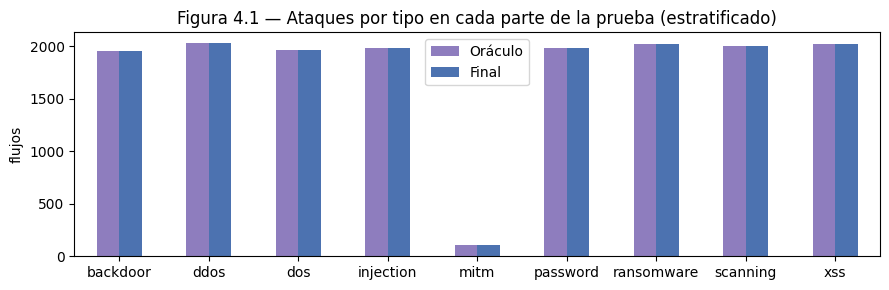

Fuente: data\splits\manifest.json (sha256 3f397ead6262…, 2026-10-11 13:31) | código: 1_prepare_splits.stratified_halves


In [11]:
t34 = pd.DataFrame({"Oráculo": sp["test_oracle"]["attack_types"], "Final": sp["test_final"]["attack_types"]})
display(t34.T)
fig, ax = plt.subplots(figsize=(9, 3))
t34.plot.bar(ax=ax, color=["#8E7DBE", "#4C72B0"]); ax.set_ylabel("flujos"); ax.set_title("Figura 4.1 — Ataques por tipo en cada parte de la prueba (estratificado)")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
fuente(SPL / "manifest.json", "1_prepare_splits.stratified_halves")

### Verificación de reproducibilidad de las particiones
Se vuelve a ejecutar `1_prepare_splits.py` (mismo código, misma configuración) hacia una carpeta **temporal** y se
comparan los hashes SHA-256 con los del manifiesto. Si coinciden, los bloques son **idénticos byte a byte**.

In [12]:
if VERIFICAR:
    tmp = Path(tempfile.mkdtemp(prefix="verif_"))
    cfg_tmp = tmp / "v.yaml"; cfg_tmp.write_text(yaml.safe_dump({"paths": {"splits_dir": str(tmp / "splits"), "outputs_dir": str(tmp / "out")}}))
    viejo = sys.argv; sys.argv = ["1_prepare_splits.py", "--config", str(cfg_tmp)]
    try:
        import contextlib, io
        with contextlib.redirect_stdout(io.StringIO()): ps.main()
    finally: sys.argv = viejo
    nuevo = common.load_json(tmp / "splits" / "manifest.json")["sha256"]
    display(pd.DataFrame({"guardado": {k: v[:16] for k, v in man["sha256"].items()},
                          "regenerado": {k: v[:16] for k, v in nuevo.items()},
                          "¿idéntico?": {k: man["sha256"][k] == nuevo[k] for k in man["sha256"]}}))
else:
    print("VERIFICAR = False: se omite.")

,guardado,regenerado,¿idéntico?
train,6eca583ade3baa40,6eca583ade3baa40,True
val,0305543962235dbd,0305543962235dbd,True
test_oracle,e1d9b775855b4fed,e1d9b775855b4fed,True
test_final,0e7cf802e1419a6d,0e7cf802e1419a6d,True


### Hallazgo: filas duplicadas entre bloques (pendiente de decisión)
TON_IoT trae muchas filas repetidas y la etapa 01 del preprocesador parte al azar **sin quitarlas**, por lo que
copias idénticas quedan a ambos lados del corte. No está declarado aún en la memoria (3.2.12).

In [13]:
leer = lambda n: common.read_table(common.find_table(SPL / n))
Tr, Va, To, Tf = leer("train"), leer("val"), leer("test_oracle"), leer("test_final")
F = list(Tr.columns); h = lambda d: pd.util.hash_pandas_object(d[F], index=False)
hTr, hVa, hTo, hTf = h(Tr), h(Va), h(To), h(Tf); nf = (Tf.y_true == 0).to_numpy()
dup = pd.Series({"filas únicas en train": hTr.nunique() / len(hTr),
                 "val idéntico a alguna fila de train": hVa.isin(set(hTr)).mean(),
                 "normales de test_final idénticos a train": hTf[nf].isin(set(hTr)).mean(),
                 "test_final idéntico a test_oracle": hTf.isin(set(hTo)).mean()})
display(dup.map("{:.1%}".format).to_frame("proporción"))
fuente(SPL / "manifest.json", "comparación de huellas de filas (pandas.util.hash_pandas_object)")

,proporción
filas únicas en train,49.1%
val idéntico a alguna fila de train,55.1%
normales de test_final idénticos a train,56.0%
test_final idéntico a test_oracle,52.0%


Fuente: data\splits\manifest.json (sha256 3f397ead6262…, 2026-10-11 13:31) | código: comparación de huellas de filas (pandas.util.hash_pandas_object)


---
# 5. Diagnóstico de las funciones objetivo *(Memoria 3.2.10)*
40 configuraciones al azar por detector; Spearman entre cada función objetivo (en `val`/objetivo) y el MCC/AUROC
reales (en `test_oracle`), con signo ajustado: **positivo = la función ordena bien**. Con N = 40, |ρ| < 0,3 no se
distingue de cero (α = 5 %).

rho_mcc                  rho_auroc               
detector       autoencoder iforest    lof autoencoder iforest    lof
metric                                                              
consistency         -0.378  -0.395  0.815      -0.313   0.370  0.102
davies_bouldin      -0.658   0.067  0.899      -0.703   0.076  0.012
reconstruction       0.797  -0.774 -0.934       0.948   0.559 -0.003
silhouette           0.790  -0.347  0.569       0.935   0.383 -0.175
stability           -0.601  -0.562  0.766      -0.837   0.093  0.168

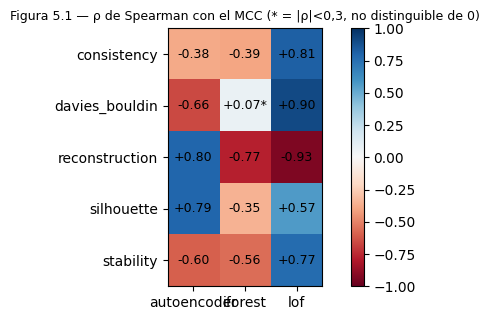

Fuente: outputs\results\diagnose_objectives_summary.json (sha256 7627897fe44b…, 2026-10-12 15:06) | código: 2_diagnose.main (--n 40, --seed 0)


In [14]:
dg = pd.DataFrame(common.load_json(RES / "diagnose_objectives_summary.json"))
piv = dg.pivot(index="metric", columns="detector", values="rho_mcc")
display(dg.pivot(index="metric", columns="detector", values=["rho_mcc", "rho_auroc"]).round(3))
fig, ax = plt.subplots(figsize=(6, 3.3))
im = ax.imshow(piv.values, cmap="RdBu", vmin=-1, vmax=1)
ax.set_xticks(range(piv.shape[1]), piv.columns); ax.set_yticks(range(piv.shape[0]), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if np.isfinite(v): ax.text(j, i, f"{v:+.2f}" + ("" if abs(v) >= 0.3 else "*"), ha="center", va="center", fontsize=9)
ax.set_title("Figura 5.1 — ρ de Spearman con el MCC (* = |ρ|<0,3, no distinguible de 0)", fontsize=9)
plt.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
fuente(RES / "diagnose_objectives_summary.json", "2_diagnose.main (--n 40, --seed 0)")

---
# 6. Optimización de hiperparámetros *(Memoria 3.2.4–3.2.8, Tablas 3.5 y 3.6)*
Optuna con TPE, 100 intentos por búsqueda, 5 semillas, sin poda temprana. Un intento se **descarta** si su latencia
en el PC supera 100/5 = 20 ms o el modelo pesa más de 50 MB. Se guardan las 5 mejores configuraciones (top-5).

In [15]:
# Se leen los 60 archivos individuales (all_studies.json es un resumen que solo guarda la ultima corrida de cada lote)
archivos = sorted((RAIZ / "outputs/optuna").glob("*_seed*.json"))
studies = pd.DataFrame([{k: v for k, v in common.load_json(f).items() if k != "top_k"} for f in archivos])
res6 = (studies.groupby(["detector", "metric"])
        .agg(búsquedas=("seed", "count"), completos=("n_completed", "sum"), descartados=("n_pruned", "sum"),
             mejor_valor_medio=("best_value", "mean"), minutos=("elapsed_s", lambda x: round(x.sum() / 60, 1))))
display(res6.round(4))
print(f"Total: {len(studies)} búsquedas, {int(studies.n_completed.sum()):,} intentos completos, {int(studies.n_pruned.sum())} descartados por límites del borde, "
      f"{studies.elapsed_s.sum() / 3600:.1f} h de cómputo.")
fuente(RAIZ / "outputs/optuna", "3_optimize.run_study (outputs/optuna/<detector>_<criterio>_seed<s>.json)",
       f"n_trials={cfg['optimization']['n_trials']}, seeds={cfg['optimization']['seeds']}, top_k={cfg['optimization']['top_k']}")

búsquedas  completos  descartados  mejor_valor_medio  minutos
detector    metric                                                                       
autoencoder oracle                  5        500            0             0.7341    147.3
            oracle_q                5        500            0             0.7435     77.0
            reconstruction          5        500            0             0.0011    103.7
            stability               5        500            0             0.9858     21.0
iforest     davies_bouldin          5        429           71             0.3068     10.6
            oracle                  5        496            4             0.2068      9.2
            oracle_q                5        489           11             0.1982     13.0
            silhouette              5        490           10             0.7451      8.0
lof         davies_bouldin          5        500            0             1.2564     15.2
            oracle                  5        499            1             0.5822    489.3
            oracle_q                5        500            0             0.7134     46.7
            silhouette              5        500            0             0.9247     14.8

Total: 60 búsquedas, 5,903 intentos completos, 97 descartados por límites del borde, 15.9 h de cómputo.
Fuente: outputs\optuna (sha256 -…, 2026-10-12 13:47) | código: 3_optimize.run_study (outputs/optuna/<detector>_<criterio>_seed<s>.json) | config: n_trials=100, seeds=[42, 43, 44, 45, 46], top_k=5


In [16]:
idx = pd.DataFrame(common.load_json(MOD / "index.json"))
print("Modelos guardados (outputs/models/index.json):")
display(idx.groupby(["config", "detector"]).size().unstack(fill_value=0))
# hiperparametros elegidos (rango 0) por detector y criterio
r0 = idx[idx["rank"] == 0].copy()
r0["params"] = r0["params"].map(lambda p: {k: (round(v, 4) if isinstance(v, float) else v) for k, v in p.items() if k not in ("random_state", "backend")})
display(r0[r0.seed == 42][["detector", "metric", "config", "params", "latency_dev_ms", "model_kb"]].sort_values(["detector", "config"]))
fuente(MOD / "index.json", "3_optimize.run_study + build_baseline (semilla 42)")

Modelos guardados (outputs/models/index.json):


detector,autoencoder,iforest,lof
config,,,
linea_base,5,5,5
optimizada,50,50,50
oraculo,50,50,50


,detector,metric,config,params,latency_dev_ms,model_kb
186,autoencoder,por_defecto,linea_base,{},NaN,63.118164
60,autoencoder,reconstruction,optimizada,"{'n_layers': 1, 'units': 80, 'latent_dim': 16,...",0.03560,59.918945
75,autoencoder,stability,optimizada,"{'n_layers': 2, 'units': 9, 'latent_dim': 4, '...",0.04175,27.782227
150,autoencoder,oracle,oraculo,"{'n_layers': 2, 'units': 121, 'latent_dim': 16...",0.28305,127.852539
165,autoencoder,oracle_q,oraculo,"{'n_layers': 2, 'units': 49, 'latent_dim': 16,...",0.11980,52.469727
180,iforest,por_defecto,linea_base,{},NaN,897.783203
0,iforest,silhouette,optimizada,"{'max_samples': 599, 'n_estimators': 100, 'max...",6.72935,1055.135742
15,iforest,davies_bouldin,optimizada,"{'max_samples': 66, 'n_estimators': 50, 'max_f...",4.05985,205.989258
90,iforest,oracle,oraculo,"{'max_samples': 363, 'n_estimators': 100, 'max...",6.38965,1190.758789
105,iforest,oracle_q,oraculo,"{'max_samples': 231, 'n_estimators': 300, 'max...",17.97390,2019.192383


Fuente: outputs\models\index.json (sha256 c526a3798f7e…, 2026-10-12 13:47) | código: 3_optimize.run_study + build_baseline (semilla 42)


### Reproducibilidad de la optimización
La optimización **no es reproducible byte a byte**, aunque todas las semillas estén fijas. La causa es el descarte
por latencia: depende del tiempo **medido** en el PC, que varía con la carga del equipo. Un intento cercano al
límite de 20 ms puede descartarse en una ejecución y no en otra, y entonces TPE sigue un camino distinto. En la
corrida guardada hubo 97 descartes (49 en `iforest/davies_bouldin/seed45`).
Con `REPETIR_UNA_BUSQUEDA = True` la celda siguiente lo muestra repitiendo una búsqueda (en una prueba, la
búsqueda iforest/silhouette/42 dio 0,7602 frente a 0,7611 guardado: cercano, pero no idéntico).

In [17]:
if REPETIR_UNA_BUSQUEDA:
    Xtr, _ = common.load_split(cfg, "train"); Xv, _ = common.load_split(cfg, "val"); cal, obj = common.split_val(Xv, cfg)
    tmp = Path(tempfile.mkdtemp()); cfg2 = common.deep_merge(cfg, {"paths": {"outputs_dir": str(tmp)}})
    r = opt.run_study(cfg2, "iforest", "silhouette", 42, cfg["optimization"]["n_trials"], {"train": Xtr, "calib": cal, "obj": obj})
    g = common.load_json(RAIZ / "outputs/optuna/iforest_silhouette_seed42.json")
    display(pd.DataFrame({"guardado": [g["best_value"], g["n_pruned"], g["best_params"]],
                          "repetido": [r["best_value"], r["n_pruned"], r["best_params"]]}, index=["mejor valor", "descartados", "parámetros"]))
else:
    print("REPETIR_UNA_BUSQUEDA = False: se omite (tarda ~2 min).")

REPETIR_UNA_BUSQUEDA = False: se omite (tarda ~2 min).


---
# 7. Medición en el dispositivo de borde *(Memoria 3.2.8, etapa 2)* — **PENDIENTE**
`src/4_edge_benchmark.py` debe ejecutarse en la Raspberry Pi 5 con `outputs/models/` y `data/splits/edge_sample.csv`.
Mientras tanto, la única referencia de costo es la **latencia mediana en el PC** registrada durante la búsqueda
(no reemplaza la medición en la Pi).

In [18]:
ep = RES / "edge_benchmark.csv"
if ep.exists():
    display(pd.read_csv(ep).head()); fuente(ep, "4_edge_benchmark.main")
else:
    lat = idx.groupby(["detector", "config"])[["latency_dev_ms", "model_kb"]].median().round(3)
    print("edge_benchmark.csv NO existe -> referencia provisional (PC, mediana de 50 inferencias):")
    display(lat); fuente(MOD / "index.json", "3_optimize.measure_latency_ms (PC de desarrollo)")

edge_benchmark.csv NO existe -> referencia provisional (PC, mediana de 50 inferencias):


latency_dev_ms  model_kb
detector    config                              
autoencoder linea_base             NaN    63.118
            optimizada           0.040    45.985
            oraculo              0.115    78.560
iforest     linea_base             NaN   916.174
            optimizada           6.431  1122.249
            oraculo              7.568  1167.164
lof         linea_base             NaN  2446.136
            optimizada           2.047  5102.390
            oraculo              1.088  4887.546

Fuente: outputs\models\index.json (sha256 c526a3798f7e…, 2026-10-12 13:47) | código: 3_optimize.measure_latency_ms (PC de desarrollo)


---
# 8. Evaluación final en `test_final` *(Memoria 3.2.9)*
Primero se verifica la integridad (SHA-256) de las partes de prueba. Luego se resumen los resultados guardados por
`5_evaluate.py`. **Recordatorio:** la elección del modelo es la de rango 0 (falta la etapa del borde).

In [19]:
ev.verify_integrity(cfg)
fe = pd.read_csv(RES / "final_evaluation.csv")
if VERIFICAR:   # reevalua los modelos de la semilla 42 y compara con lo guardado
    X, y, _ = common.load_labeled(cfg, "test_final")
    elegidos = [e for e in ev.select_entries(common.load_json(MOD / "index.json"), None) if e["seed"] == 42]
    comp = []
    for e in elegidos:
        m, _, _ = ev.evaluate_entry(e, MOD, X, y, cfg)
        g = fe[(fe.detector == e["detector"]) & (fe.metric == e["metric"]) & (fe.seed == 42) & (fe.config == e["config"])]
        comp.append({"detector": e["detector"], "criterio": e["metric"], "MCC guardado": g.MCC.iloc[0], "MCC recalculado": m["MCC"]})
    comp = pd.DataFrame(comp); comp["¿idéntico?"] = np.isclose(comp["MCC guardado"], comp["MCC recalculado"], atol=1e-12)
    display(comp.round(6)); print("Todos idénticos:", bool(comp["¿idéntico?"].all()))

Integridad de los bloques de prueba verificada (SHA-256).


,detector,criterio,MCC guardado,MCC recalculado,¿idéntico?
0,autoencoder,oracle,0.778003,0.778003,True
1,autoencoder,oracle_q,0.735178,0.735178,True
2,autoencoder,por_defecto,0.210376,0.210376,True
3,autoencoder,reconstruction,0.551894,0.551894,True
4,autoencoder,stability,-0.138131,-0.138131,True
5,iforest,davies_bouldin,0.127687,0.127687,True
6,iforest,oracle,0.208071,0.208071,True
7,iforest,oracle_q,0.197395,0.197395,True
8,iforest,por_defecto,0.115443,0.115443,True
9,iforest,silhouette,0.194823,0.194823,True


Todos idénticos: True


### Tabla 8.1 — Capacidad de detección por detector y criterio (media ± desviación sobre 5 semillas)

In [20]:
d = fe[fe.config != "linea_base_nativa"]
agg = d.groupby(["detector", "config", "metric"]).agg(
    MCC=("MCC", "mean"), MCC_sd=("MCC", "std"), MCC_pi10=("MCC_pi10", "mean"), AUROC=("AUROC", "mean"),
    AUPRC=("AUPRC", "mean"), Recall=("Recall", "mean"), FPR=("FPR", "mean"), semillas=("seed", "count")).round(3)
orden = {"linea_base": 0, "optimizada": 1, "oraculo": 2}
agg = agg.reset_index().sort_values(["detector", "config"], key=lambda s: s.map(orden).fillna(s)).set_index(["detector", "config", "metric"])
display(agg)
fuente(RES / "final_evaluation.csv", "5_evaluate.evaluate_entry",
       f"q={cfg['threshold']['q']}, report_prevalences={cfg['split']['report_prevalences']}")

MCC  MCC_sd  MCC_pi10  AUROC  AUPRC  Recall    FPR  semillas
detector    config     metric                                                                        
autoencoder linea_base por_defecto     0.184   0.196     0.199  0.862  0.924   0.235  0.048         5
            optimizada reconstruction  0.556   0.004     0.622  0.906  0.957   0.697  0.046         5
                       stability      -0.132   0.055    -0.057  0.664  0.803   0.011  0.052         5
            oraculo    oracle          0.737   0.059     0.729  0.922  0.964   0.860  0.047         5
                       oracle_q        0.746   0.019     0.586  0.921  0.954   0.909  0.126         5
iforest     linea_base por_defecto     0.095   0.047     0.091  0.622  0.826   0.115  0.046         5
            optimizada davies_bouldin  0.042   0.055     0.038  0.557  0.802   0.081  0.051         5
                       silhouette      0.040   0.088     0.044  0.656  0.833   0.084  0.047         5
            oraculo    oracle          0.209   0.010     0.234  0.647  0.848   0.242  0.048         5
                       oracle_q        0.201   0.011     0.218  0.668  0.846   0.243  0.055         5
lof         linea_base por_defecto     0.377   0.000     0.452  0.758  0.926   0.474  0.046         5
            optimizada davies_bouldin  0.583   0.000     0.648  0.831  0.951   0.724  0.044         5
                       silhouette      0.577   0.000     0.643  0.823  0.950   0.718  0.044         5
            oraculo    oracle          0.584   0.000     0.651  0.824  0.948   0.724  0.043         5
                       oracle_q        0.716   0.109     0.607  0.883  0.966   0.865  0.102         5

Fuente: outputs\results\final_evaluation.csv (sha256 2eee24d8071d…, 2026-11-13 17:37) | código: 5_evaluate.evaluate_entry | config: q=0.95, report_prevalences=[0.05, 0.1]


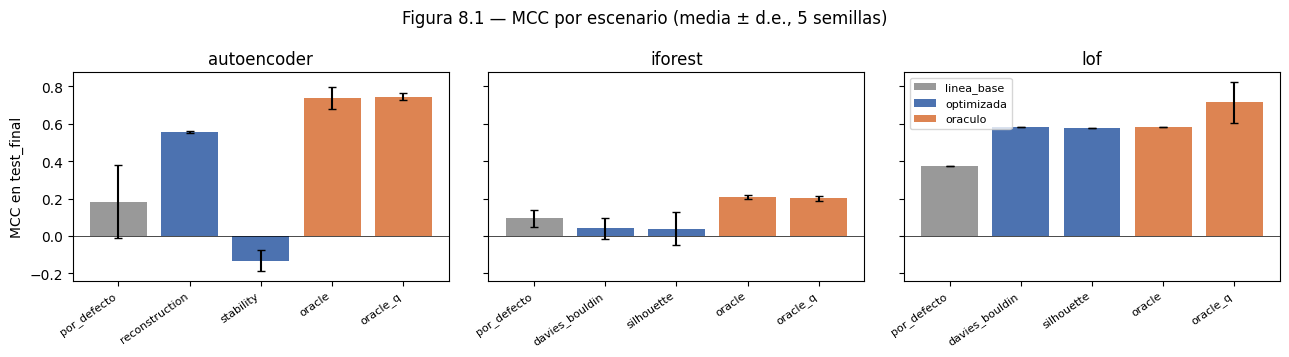

Fuente: outputs\results\final_evaluation.csv (sha256 2eee24d8071d…, 2026-11-13 17:37) | código: 5_evaluate.main


In [21]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
col = {"linea_base": "#999999", "optimizada": "#4C72B0", "oraculo": "#DD8452"}
for ax, (det, g) in zip(axs, agg.reset_index().groupby("detector")):
    ax.bar(range(len(g)), g.MCC, yerr=g.MCC_sd.fillna(0), color=[col[c] for c in g.config], capsize=3)
    ax.set_xticks(range(len(g)), g.metric, rotation=35, ha="right", fontsize=8); ax.set_title(det); ax.axhline(0, color="k", lw=.5)
axs[0].set_ylabel("MCC en test_final")
for c, k in col.items(): axs[2].bar(0, 0, color=k, label=c)
axs[2].legend(fontsize=8); fig.suptitle("Figura 8.1 — MCC por escenario (media ± d.e., 5 semillas)"); plt.tight_layout(); plt.show()
fuente(RES / "final_evaluation.csv", "5_evaluate.main")

### Tabla 8.2 — Mejor criterio no supervisado vs. línea base y oráculo (criterio de la memoria 3.2.9: mejora si Δ − 2EE > 0)

In [22]:
bal = pd.read_csv(RES / "balance.csv"); display(bal)
fuente(RES / "balance.csv", "5_evaluate.summarize")
bpm = pd.read_csv(RES / "balance_por_metrica.csv")
display(bpm[["detector", "metric", "config", "mcc_medio", "mcc_std", "delta_mcc", "delta_se", "dist_oraculo"]].round(4))
fuente(RES / "balance_por_metrica.csv", "5_evaluate.summarize")

,detector,mcc_linea_base,mejor_metrica,mcc_medio,mcc_std,n_semillas,delta_mcc,mcc_oraculo,mcc_oraculo_q,dist_oraculo,estado_vs_base
0,autoencoder,0.1835,reconstruction,0.5560,0.0036,5,0.3725,0.7371,0.7459,0.1811,mejora
1,iforest,0.0945,davies_bouldin,0.0415,0.0546,5,-0.0530,0.2087,0.2006,0.1672,empeora
2,lof,0.3771,davies_bouldin,0.5834,0.0000,5,0.2063,0.5841,0.7160,0.0007,mejora


Fuente: outputs\results\balance.csv (sha256 e37cd17d1c79…, 2026-11-13 17:37) | código: 5_evaluate.summarize


,detector,metric,config,mcc_medio,mcc_std,delta_mcc,delta_se,dist_oraculo
0,autoencoder,oracle,oraculo,0.7371,0.0594,0.5536,0.1109,0.0000
1,autoencoder,oracle_q,oraculo,0.7459,0.0189,0.5624,0.0858,-0.0087
2,autoencoder,reconstruction,optimizada,0.5560,0.0036,0.3725,0.0876,0.1811
3,autoencoder,stability,optimizada,-0.1325,0.0549,-0.3160,0.1026,0.8696
4,iforest,davies_bouldin,optimizada,0.0415,0.0546,-0.0530,0.0220,0.1672
5,iforest,oracle,oraculo,0.2087,0.0100,0.1142,0.0168,0.0000
6,iforest,oracle_q,oraculo,0.2006,0.0106,0.1060,0.0169,0.0082
7,iforest,silhouette,optimizada,0.0403,0.0880,-0.0543,0.0398,0.1685
8,lof,davies_bouldin,optimizada,0.5834,0.0000,0.2063,0.0000,0.0007
9,lof,oracle,oraculo,0.5841,0.0000,0.2070,0.0000,0.0000


Fuente: outputs\results\balance_por_metrica.csv (sha256 0edfdd887aa2…, 2026-11-13 17:37) | código: 5_evaluate.summarize


### Contraste de la hipótesis (3 condiciones de la memoria 3.2.9)

In [23]:
hyp = common.load_json(RES / "hypothesis_check.json")
display(pd.DataFrame(hyp["por_detector"]).T)
c1 = all(v["estado_vs_base"] != "empeora" for v in hyp["por_detector"].values())
c3 = all(v["separable"] for v in hyp["por_detector"].values())
print(f"(1) ninguna ganadora empeora la línea base: {c1}")
print(f"(2) las ganadoras difieren entre detectores: {hyp['difieren']}  {hyp['metricas_ganadoras']}")
print(f"(3) margen sobre la segunda > dispersión entre semillas en todos: {c3}")
print(f"=> HIPÓTESIS RESPALDADA: {hyp['hipotesis_soportada']}  (provisional: falta la selección con mediciones del borde)")
fuente(RES / "hypothesis_check.json", "5_evaluate.summarize")

,mejor_metrica,estado_vs_base,margen_sobre_segunda,dispersion_semillas,separable
autoencoder,reconstruction,mejora,0.688466,0.029293,True
iforest,davies_bouldin,empeora,0.001269,0.071291,False
lof,davies_bouldin,mejora,0.00604,0.0,True


(1) ninguna ganadora empeora la línea base: False
(2) las ganadoras difieren entre detectores: True  {'autoencoder': 'reconstruction', 'iforest': 'davies_bouldin', 'lof': 'davies_bouldin'}
(3) margen sobre la segunda > dispersión entre semillas en todos: False
=> HIPÓTESIS RESPALDADA: False  (provisional: falta la selección con mediciones del borde)
Fuente: outputs\results\hypothesis_check.json (sha256 7f46001b2f59…, 2026-11-13 17:37) | código: 5_evaluate.summarize


### Tabla 8.3 — Recall por tipo de ataque (mejor criterio y línea base)

In [24]:
rpa = pd.read_csv(RES / "recall_por_ataque.csv")
sel = pd.concat([rpa[(rpa.detector == b.detector) & (rpa.metric.isin([b.mejor_metrica, "por_defecto"]))] for b in bal.itertuples()])
display(sel.pivot_table(index=["detector", "metric"], columns="attack_type", values="recall").round(2))
fuente(RES / "recall_por_ataque.csv", "5_evaluate.main")

attack_type                 backdoor  ddos   dos  injection  mitm  password  ransomware  scanning   xss
detector    metric                                                                                     
autoencoder por_defecto         0.21  0.34  0.22       0.13  0.38      0.08        0.09      0.37  0.43
            reconstruction      1.00  0.95  0.92       0.17  0.40      0.28        0.34      1.00  0.93
iforest     davies_bouldin      0.00  0.02  0.01       0.38  0.29      0.05        0.00      0.00  0.17
            por_defecto         0.00  0.02  0.01       0.50  0.34      0.18        0.00      0.00  0.19
lof         davies_bouldin      1.00  0.92  0.92       0.05  0.17      0.25        1.00      0.98  0.70
            por_defecto         0.00  0.33  0.10       0.77  0.82      0.13        0.68      0.85  0.89

Fuente: outputs\results\recall_por_ataque.csv (sha256 ea44ad7204a4…, 2026-11-13 17:37) | código: 5_evaluate.main


### Tabla 8.4 — Sensibilidad al umbral (solo descriptivo, no se usa para elegir)

In [25]:
qcols = [c for c in fe.columns if c.startswith("MCC_q")]
display(d.groupby(["detector", "config", "metric"])[qcols].mean().round(3))
fuente(RES / "final_evaluation.csv", "5_evaluate.evaluate_entry", f"sensitivity_q={cfg['threshold']['sensitivity_q']}")

MCC_q90  MCC_q95  MCC_q99
detector    config     metric                                   
autoencoder linea_base por_defecto       0.509    0.184   -0.015
            optimizada reconstruction    0.575    0.556    0.089
                       stability        -0.077   -0.132   -0.038
            oraculo    oracle            0.751    0.737    0.129
                       oracle_q          0.632    0.439    0.036
iforest     linea_base por_defecto       0.146    0.095   -0.045
            optimizada davies_bouldin    0.100    0.042   -0.024
                       silhouette        0.081    0.040   -0.012
            oraculo    oracle            0.173    0.209   -0.010
                       oracle_q          0.174    0.120   -0.036
lof         linea_base por_defecto       0.477    0.377    0.276
            optimizada davies_bouldin    0.548    0.583    0.486
                       silhouette        0.548    0.577    0.498
            oraculo    oracle            0.554    0.584    0.488
                       oracle_q          0.637    0.513    0.444

Fuente: outputs\results\final_evaluation.csv (sha256 2eee24d8071d…, 2026-11-13 17:37) | código: 5_evaluate.evaluate_entry | config: sensitivity_q=[0.9, 0.95, 0.99]


### Figura 8.2 — Frente de Pareto MCC vs latencia (PROVISIONAL: latencia del PC)

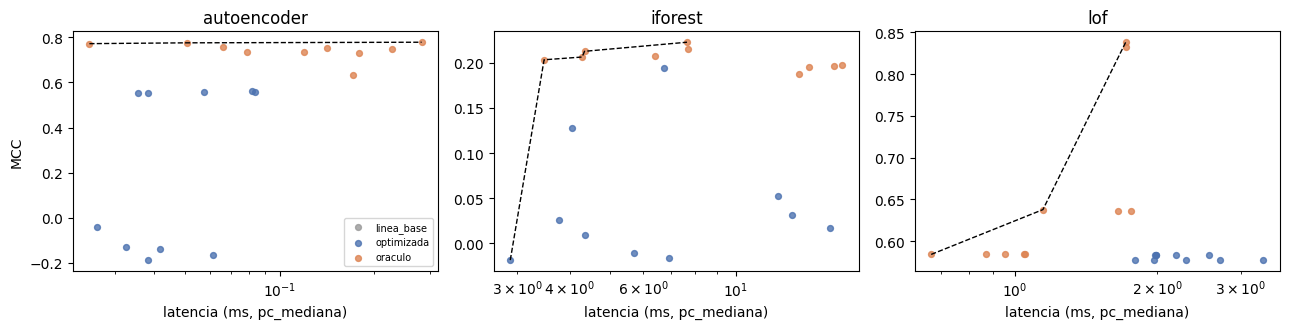

Fuente: outputs\results\pareto_mcc_latencia.csv (sha256 1c0e8b504aa8…, 2026-11-13 17:37) | código: 5_evaluate.pareto_front


In [26]:
par = pd.read_csv(RES / "pareto_mcc_latencia.csv")
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (det, g) in zip(axs, par.groupby("detector")):
    for c, k in col.items():
        gg = g[g.config == c]; ax.scatter(gg.latencia_ms, gg.MCC, c=k, s=18, label=c, alpha=.8)
    f = g[g.en_frente].sort_values("latencia_ms"); ax.plot(f.latencia_ms, f.MCC, "k--", lw=1)
    ax.set_xscale("log"); ax.set_title(det); ax.set_xlabel(f"latencia (ms, {g.fuente_latencia.iloc[0]})")
axs[0].set_ylabel("MCC"); axs[0].legend(fontsize=7); plt.tight_layout(); plt.show()
fuente(RES / "pareto_mcc_latencia.csv", "5_evaluate.pareto_front")

---
# 9. Tablas para la memoria (`outputs/tables/*.tex`)
Generadas por `src/6_report.py` y pensadas para incluirse con `\input{}`: ningún número se copia a mano.

In [27]:
for f in sorted((RAIZ / "outputs/tables").glob("*.tex")):
    txt = f.read_text(encoding="utf-8")
    print(f"{f.name:28s} {'PENDIENTE' if '[Pendiente]' in txt else 'con datos'}  (sha256 {sha(f)}…)")

tab_mock_balance.tex         con datos  (sha256 caa66d7a5327…)
tab_mock_hardware.tex        PENDIENTE  (sha256 3a6f8750680d…)
tab_mock_performance.tex     con datos  (sha256 948ff7db2860…)


---
# 10. Resumen: disponible, pendiente y puntos para la reunión

**Disponible y verificado**
- Particiones reproducibles byte a byte (hashes idénticos al regenerarlas).
- Evaluación reproducible exactamente (MCC recalculado = guardado) y con integridad de `test_final` verificada.
- Diagnóstico (40 configuraciones × 3 detectores), 60 búsquedas de Optuna (3 detectores × 4 criterios × 5 semillas,
  incluidos los dos oráculos), evaluación final y tablas.

**Provisional**
- La elección del modelo (rango 0) y el frente de Pareto (latencia del PC), hasta medir en la Raspberry Pi.
- Por lo tanto también el contraste de la hipótesis.

**Pendiente**
- Medición en la Raspberry Pi 5 (`4_edge_benchmark.py`), luego `5_evaluate.py` y `6_report.py` de nuevo.

**Para discutir**
1. Filas duplicadas entre bloques (sección 4): decidir si se deduplica en `1_prepare_splits.py` (cambiaría los
   resultados) o se declara como limitación en 3.2.12.
2. Reproducibilidad aproximada de la optimización por el descarte basado en latencia medida (sección 6).